In [136]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

**Data Collection and Processing**

In [137]:
# loading the csv data to a Pandas DataFrame
heart_data = pd.read_csv('/content/data.csv')

In [138]:
# print first 5 rows of the dataset
heart_data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [139]:
# print last 5 rows of the dataset
heart_data.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [140]:
# number of rows and columns in the dataset
heart_data.shape

(303, 14)

In [141]:
# getting some info about the data
heart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [142]:
# checking for missing values
heart_data.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [143]:
# statistical measures about the data
heart_data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [144]:
# checking the distribution of Target Variable
heart_data['target'].value_counts()

,count
target,
1,165
0,138


1 --> Defective Heart

0 --> Healthy Heart

**Splitting the Features and Target**

In [145]:
X = heart_data.drop(columns='target', axis=1)
Y = heart_data['target']

In [146]:
print(X)

     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
0     63    1   3       145   233    1        0      150      0      2.3   
1     37    1   2       130   250    0        1      187      0      3.5   
2     41    0   1       130   204    0        0      172      0      1.4   
3     56    1   1       120   236    0        1      178      0      0.8   
4     57    0   0       120   354    0        1      163      1      0.6   
..   ...  ...  ..       ...   ...  ...      ...      ...    ...      ...   
298   57    0   0       140   241    0        1      123      1      0.2   
299   45    1   3       110   264    0        1      132      0      1.2   
300   68    1   0       144   193    1        1      141      0      3.4   
301   57    1   0       130   131    0        1      115      1      1.2   
302   57    0   1       130   236    0        0      174      0      0.0   

     slope  ca  thal  
0        0   0     1  
1        0   0     2  
2        2   0    

In [147]:
print(Y)

0      1
1      1
2      1
3      1
4      1
      ..
298    0
299    0
300    0
301    0
302    0
Name: target, Length: 303, dtype: int64


**Splitting the Data into Training data & Test Data**

In [148]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=2)

In [149]:
print(X.shape, X_train.shape, X_test.shape)

(303, 13) (242, 13) (61, 13)


**Model Train**

**Logistic Regression**

In [150]:
model = LogisticRegression()

In [151]:
# training the LogisticRegression model with Training data
model.fit(X_train, Y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

**Model Evaluation**

**Accuracy Score**

In [152]:
# accuracy on training data
X_train_prediction = model.predict(X_train)
training_data_accuracy = accuracy_score(X_train_prediction, Y_train)

In [153]:
print('Accuracy on Training data : ', training_data_accuracy)

Accuracy on Training data :  0.8512396694214877


In [154]:
# accuracy on test data
X_test_prediction = model.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, Y_test)

In [155]:
print('Accuracy on Test data : ', test_data_accuracy)

Accuracy on Test data :  0.819672131147541


**Building a Predictive System**

In [156]:
input_data = (48,0,2,130,275,0,1,139,0,0.2,2,0,2)
#input_data = (58,0,0,170,225,1,0,146,1,2.8,1,2,1)

# change the input data to a numpy array
input_data_as_numpy_array= np.asarray(input_data)

# reshape the numpy array as we are predicting for only on instance
input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)

prediction = model.predict(input_data_reshaped)
print(prediction)

if (prediction[0]== 0):
  print('The Person does not have a Heart Disease')
else:
  print('The Person has Heart Disease')

[1]
The Person has Heart Disease


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(



**Plotting**

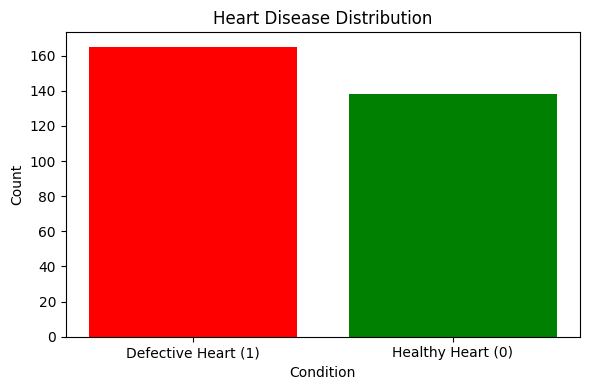

In [157]:
# Target Distribution (Bar Chart)
target_counts = heart_data['target'].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(['Defective Heart (1)', 'Healthy Heart (0)'], target_counts, color=['red', 'green'])
plt.title('Heart Disease Distribution')
plt.xlabel('Condition')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

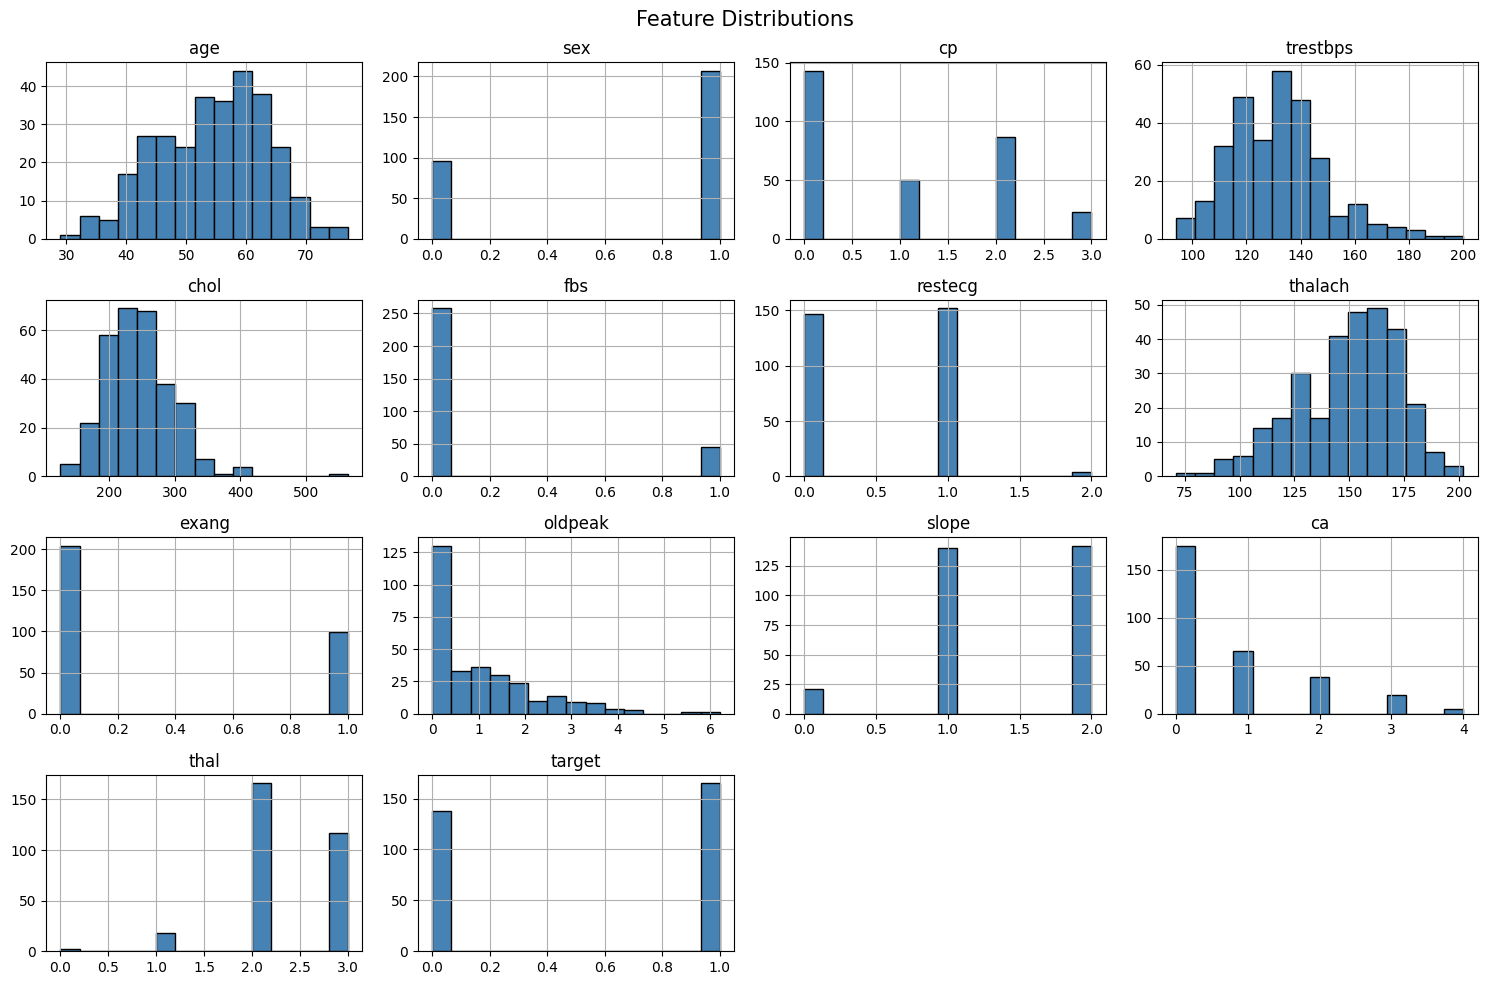

In [158]:
# Histogram of all features
heart_data.hist(figsize=(15, 10), bins=15, color='steelblue', edgecolor='black')
plt.suptitle('Feature Distributions', fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# Correlation Heatmap
corr = heart_data.corr()
fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.matshow(corr, cmap='coolwarm')
fig.colorbar(cax)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)
plt.title('Feature Correlation Heatmap', pad=20)
plt.tight_layout()
plt.show()

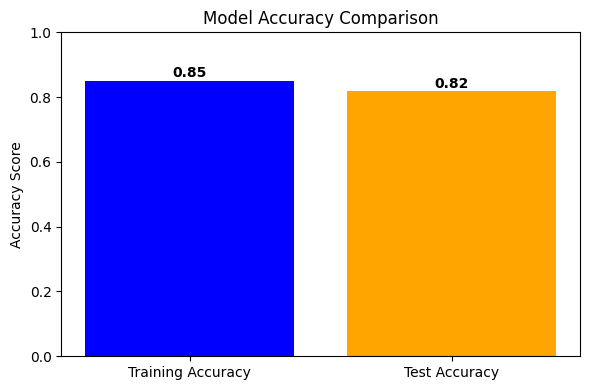

In [160]:
# Training vs Test Accuracy Bar Chart
labels = ['Training Accuracy', 'Test Accuracy']
values = [training_data_accuracy, test_data_accuracy]

plt.figure(figsize=(6, 4))
plt.bar(labels, values, color=['blue', 'orange'])
plt.ylim(0, 1)
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy Score')
for i, v in enumerate(values):
    plt.text(i, v + 0.01, f'{v:.2f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# 2nd Model

In [161]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [162]:
# ---- K-Nearest Neighbors ----
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, Y_train)

knn_train_pred = knn_model.predict(X_train)
knn_test_pred = knn_model.predict(X_test)

knn_train_acc = accuracy_score(Y_train, knn_train_pred)
knn_test_acc = accuracy_score(Y_test, knn_test_pred)

print("KNN - Training Accuracy:", knn_train_acc)
print("KNN - Test Accuracy:", knn_test_acc)

KNN - Training Accuracy: 0.78099173553719
KNN - Test Accuracy: 0.6229508196721312


**Plotting KNN Values**

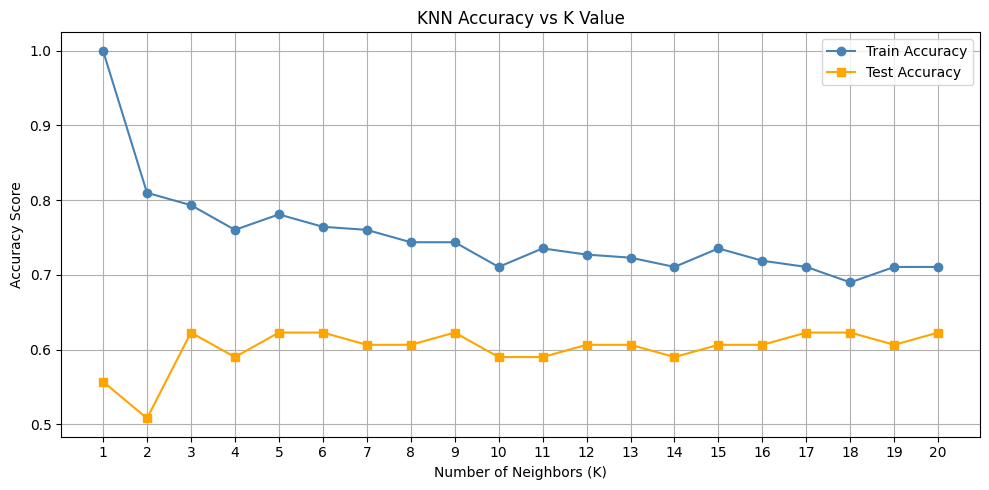

In [163]:
# Find best K value
k_range = range(1, 21)
k_train_scores = []
k_test_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, Y_train)
    k_train_scores.append(accuracy_score(Y_train, knn.predict(X_train)))
    k_test_scores.append(accuracy_score(Y_test, knn.predict(X_test)))

plt.figure(figsize=(10, 5))
plt.plot(k_range, k_train_scores, marker='o', label='Train Accuracy', color='steelblue')
plt.plot(k_range, k_test_scores, marker='s', label='Test Accuracy', color='orange')
plt.title('KNN Accuracy vs K Value')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy Score')
plt.xticks(k_range)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

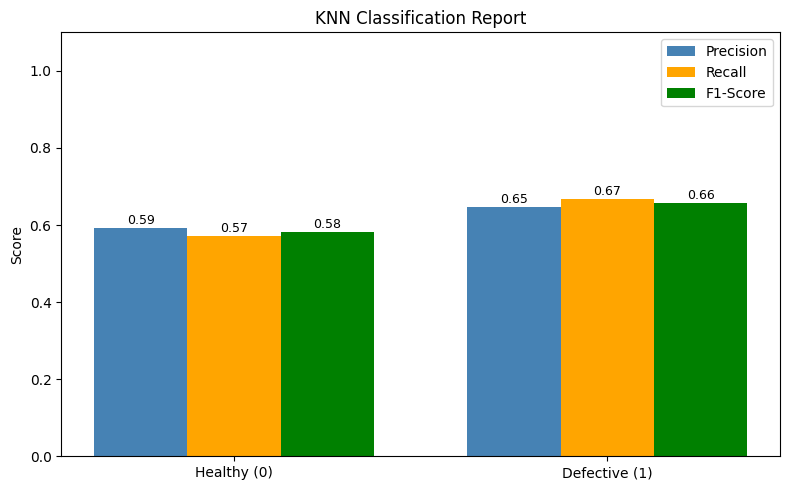

In [164]:
# Classification Report as Bar Chart
from sklearn.metrics import classification_report
import numpy as np

report = classification_report(Y_test, knn_test_pred, output_dict=True)

categories   = ['Healthy (0)', 'Defective (1)']
precision    = [report['0']['precision'],  report['1']['precision']]
recall       = [report['0']['recall'],     report['1']['recall']]
f1_score_val = [report['0']['f1-score'],   report['1']['f1-score']]

x = np.arange(len(categories))
width = 0.25

plt.figure(figsize=(8, 5))
plt.bar(x - width,   precision,    width, label='Precision', color='steelblue')
plt.bar(x,           recall,       width, label='Recall',    color='orange')
plt.bar(x + width,   f1_score_val, width, label='F1-Score',  color='green')

plt.xticks(x, categories)
plt.ylim(0, 1.1)
plt.ylabel('Score')
plt.title('KNN Classification Report')
plt.legend()

for i in range(len(categories)):
    plt.text(i - width,   precision[i]    + 0.01, f'{precision[i]:.2f}',    ha='center', fontsize=9)
    plt.text(i,           recall[i]       + 0.01, f'{recall[i]:.2f}',       ha='center', fontsize=9)
    plt.text(i + width,   f1_score_val[i] + 0.01, f'{f1_score_val[i]:.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

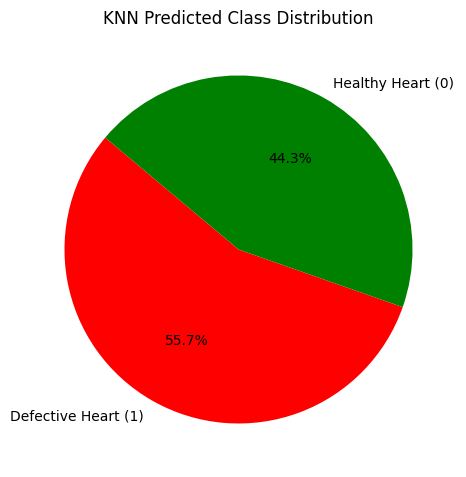

In [165]:
# Prediction Distribution
pred_counts = pd.Series(knn_test_pred).value_counts()

plt.figure(figsize=(5, 5))
plt.pie(pred_counts,
        labels=['Defective Heart (1)', 'Healthy Heart (0)'],
        autopct='%1.1f%%',
        colors=['red', 'green'],
        startangle=140)
plt.title('KNN Predicted Class Distribution')
plt.tight_layout()
plt.show()

/tmp/ipykernel_646/2803099666.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['', 'Healthy (0)', 'Defective (1)'])
/tmp/ipykernel_646/2803099666.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['', 'Healthy (0)', 'Defective (1)'])


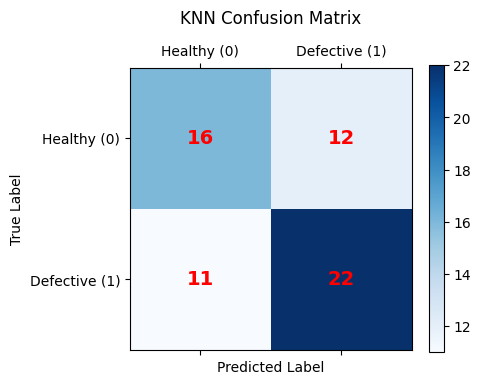

In [166]:
# Confusion Matrix
cm = confusion_matrix(Y_test, knn_test_pred)

fig, ax = plt.subplots(figsize=(5, 4))
cax = ax.matshow(cm, cmap='Blues')
fig.colorbar(cax)

ax.set_xticklabels(['', 'Healthy (0)', 'Defective (1)'])
ax.set_yticklabels(['', 'Healthy (0)', 'Defective (1)'])
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
ax.set_title('KNN Confusion Matrix', pad=15)

for (i, j), val in np.ndenumerate(cm):
    ax.text(j, i, str(val), ha='center', va='center', fontsize=14, color='red', fontweight='bold')

plt.tight_layout()
plt.show()

# Accuracy Comparison

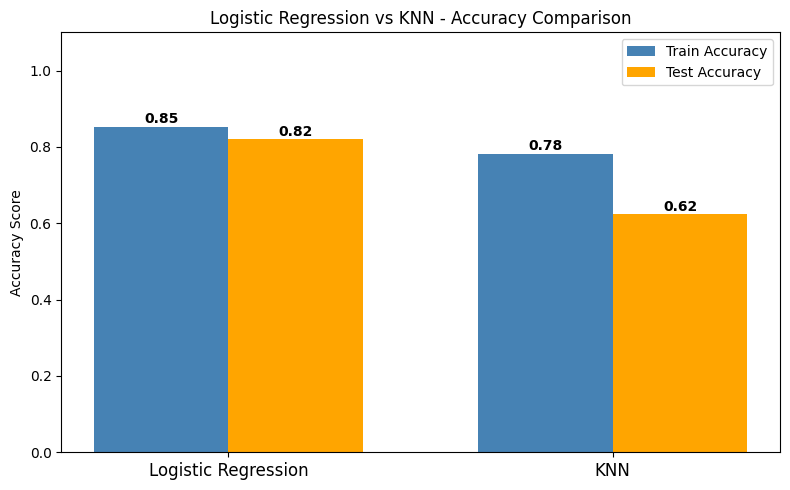

In [167]:
# Accuracy Comparison
models = ['Logistic Regression', 'KNN']
train_accs = [training_data_accuracy, knn_train_acc]
test_accs  = [test_data_accuracy, knn_test_acc]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, train_accs, width, label='Train Accuracy', color='steelblue')
plt.bar(x + width/2, test_accs,  width, label='Test Accuracy',  color='orange')
plt.xticks(x, models, fontsize=12)
plt.ylim(0, 1.1)
plt.ylabel('Accuracy Score')
plt.title('Logistic Regression vs KNN - Accuracy Comparison')
plt.legend()

for i, (tr, te) in enumerate(zip(train_accs, test_accs)):
    plt.text(i - width/2, tr + 0.01, f'{tr:.2f}', ha='center', fontsize=10, fontweight='bold')
    plt.text(i + width/2, te + 0.01, f'{te:.2f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

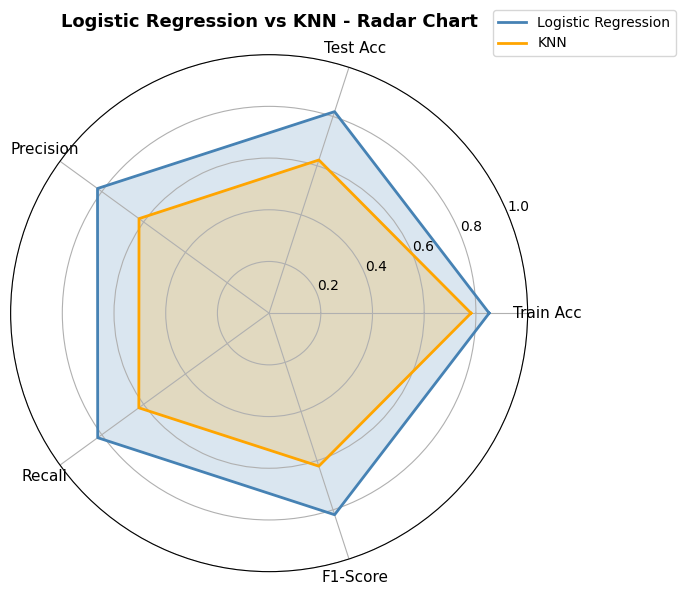

In [168]:
# Radar Chart
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

categories = ['Train Acc', 'Test Acc', 'Precision', 'Recall', 'F1-Score']

lr_vals  = [training_data_accuracy,
            test_data_accuracy,
            lr_report['weighted avg']['precision'],
            lr_report['weighted avg']['recall'],
            lr_report['weighted avg']['f1-score']]

knn_vals = [knn_train_acc,
            knn_test_acc,
            knn_report['weighted avg']['precision'],
            knn_report['weighted avg']['recall'],
            knn_report['weighted avg']['f1-score']]

# Close the radar loop
lr_vals  += lr_vals[:1]
knn_vals += knn_vals[:1]

angles = [n / float(len(categories)) * 2 * np.pi for n in range(len(categories))]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

ax.plot(angles, lr_vals,  linewidth=2, linestyle='solid', label='Logistic Regression', color='steelblue')
ax.fill(angles, lr_vals,  alpha=0.2, color='steelblue')

ax.plot(angles, knn_vals, linewidth=2, linestyle='solid', label='KNN', color='orange')
ax.fill(angles, knn_vals, alpha=0.2, color='orange')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1)
ax.set_title('Logistic Regression vs KNN - Radar Chart', fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.tight_layout()
plt.show()

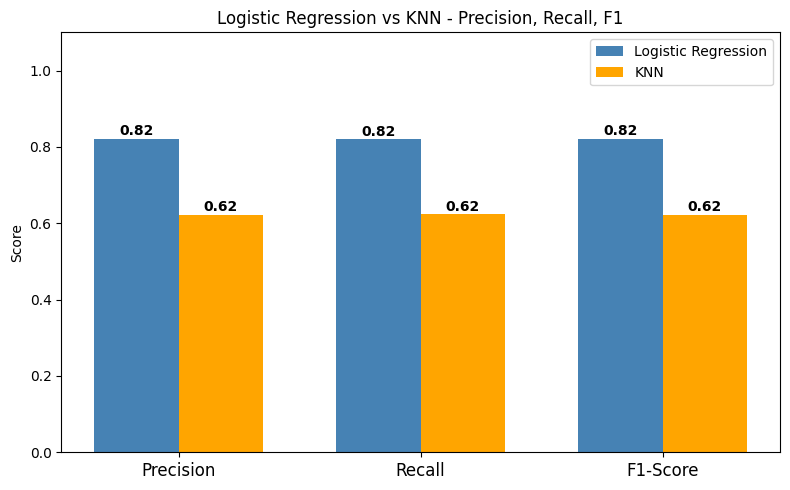

In [169]:
# Precision, Recall, F1 Comparison
from sklearn.metrics import classification_report

lr_report  = classification_report(Y_test, X_test_prediction, output_dict=True)
knn_report = classification_report(Y_test, knn_test_pred,     output_dict=True)

metrics = ['Precision', 'Recall', 'F1-Score']
lr_scores  = [lr_report['weighted avg']['precision'],
              lr_report['weighted avg']['recall'],
              lr_report['weighted avg']['f1-score']]
knn_scores = [knn_report['weighted avg']['precision'],
              knn_report['weighted avg']['recall'],
              knn_report['weighted avg']['f1-score']]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, lr_scores,  width, label='Logistic Regression', color='steelblue')
plt.bar(x + width/2, knn_scores, width, label='KNN',                 color='orange')
plt.xticks(x, metrics, fontsize=12)
plt.ylim(0, 1.1)
plt.ylabel('Score')
plt.title('Logistic Regression vs KNN - Precision, Recall, F1')
plt.legend()

for i, (lr, knn) in enumerate(zip(lr_scores, knn_scores)):
    plt.text(i - width/2, lr  + 0.01, f'{lr:.2f}',  ha='center', fontsize=10, fontweight='bold')
    plt.text(i + width/2, knn + 0.01, f'{knn:.2f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()